In [526]:
import pandas as pd 
import numpy as np 
from matplotlib import pyplot as plt 

In [527]:
df = pd.read_csv('9-homeprices_banglore.csv')
df.head()

,area,bedrooms,price
0,1056,2,39.07
1,2600,4,120.00
2,1440,3,62.00
3,1521,3,75.00
4,1200,2,51.00


In [528]:
from sklearn.preprocessing import MinMaxScaler

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scaled_x = scaler_x.fit_transform(df.drop('price' , axis=1))
scaled_y = scaler_y.fit_transform(df[['price']])

In [529]:
scaled_x

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [530]:
scaler_y.inverse_transform(scaled_y)

array([[ 39.07],
       [120.  ],
       [ 62.  ],
       [ 75.  ],
       [ 51.  ],
       [ 38.  ],
       [135.  ],
       [155.  ],
       [ 50.  ],
       [167.  ],
       [ 82.  ],
       [140.  ],
       [ 38.  ],
       [ 40.  ],
       [101.  ],
       [ 42.  ],
       [ 48.  ],
       [ 60.  ],
       [102.  ],
       [ 32.  ]])

In [531]:
scaled_y

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074],
       [0.04444444],
       [0.76296296],
       [0.91111111],
       [0.13333333],
       [1.        ],
       [0.37037037],
       [0.8       ],
       [0.04444444],
       [0.05925926],
       [0.51111111],
       [0.07407407],
       [0.11851852],
       [0.20740741],
       [0.51851852],
       [0.        ]])

In [532]:
scaled_y.shape

(20, 1)

In [533]:
scaled_y.reshape(len(scaled_y),)

array([0.05237037, 0.65185185, 0.22222222, 0.31851852, 0.14074074,
       0.04444444, 0.76296296, 0.91111111, 0.13333333, 1.        ,
       0.37037037, 0.8       , 0.04444444, 0.05925926, 0.51111111,
       0.07407407, 0.11851852, 0.20740741, 0.51851852, 0.        ])

In [534]:
def mini_batch_gradient_descent(X,y , epochs =100 , batch_size = 5 , learning_rate =0.01):
    number_of_features = X.shape[1]
    w = np.ones(shape=(number_of_features))
    b = 0 
    total_samples = X.shape[0]
    
    if batch_size > total_samples:
        batch_size = total_samples
        
    cost_list = []
    epoch_list = []
    
    num_batches = int(total_samples / batch_size)
    
    for i in range(epochs):
        random_indices = np.random.permutation(total_samples)
        X_tmp = X[random_indices]
        y_tmp = y[random_indices]
        
        for j in range(0,total_samples,batch_size):
            Xj = X_tmp[j:j+batch_size]
            yj = y_tmp[j:j+batch_size]
            
            y_predicted = np.dot(w,Xj.T) + b
            
            w_grad = -(2/len(Xj) * (Xj.T.dot(yj - y_predicted)))
            b_grad = -(2/len(Xj) * np.sum(yj - y_predicted))
            
            w = w - learning_rate * w_grad
            b = b - learning_rate * b_grad
            
            cost = np.mean(np.square(yj-y_predicted)) 
            
        if i % 10 == 0:
            cost_list.append(cost)
            epoch_list.append(i)
            
    return w , b , cost , cost_list , epoch_list 

w , b , cost , cost_list , epoch_list = mini_batch_gradient_descent(
    scaled_x,
    scaled_y.reshape(len(scaled_y)) ,
    epochs = 120 ,
    batch_size = 5
)

w , b , cost

(array([0.7101745 , 0.67809096]),
 np.float64(-0.2335520149927563),
 np.float64(0.007848079869883073))

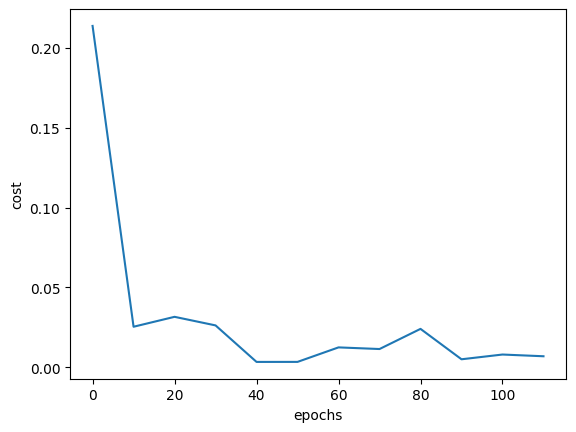

In [535]:
plt.xlabel('epochs')
plt.ylabel('cost')
plt.plot(epoch_list,cost_list)

In [536]:
def predict(area, bedrooms , w , b ):
    new_data = pd.DataFrame([[area, bedrooms]], columns=['area', 'bedrooms'])
    scaled_X = scaler_x.transform(new_data)[0]
    
    scaled_price = w[0] * scaled_X[0] + w[1] * scaled_X[1] + b
    return scaler_y.inverse_transform([[scaled_price]])[0][0] 

predict(2600,4,w,b)


np.float64(128.63491335845046)

In [537]:
w , b 

(array([0.7101745 , 0.67809096]), np.float64(-0.2335520149927563))

In [544]:
value = 0.7102815  * 0.62068966 +  0.67825295 * 0.75 + -0.2335520149927563
value

0.7160020802465337

In [545]:
scaler_y.inverse_transform([[value]])[0][0] 

np.float64(128.66028083328203)